<a href="https://colab.research.google.com/github/Bharathkumar04-git/DeepTrace/blob/main/DeepTrace_Sentence_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepTrace: Sentence-Level AI Text Detector
**Team:** Bharath Kumar (24MIS0247), Sanjeev (24MIS0554)

Paste any text and DeepTrace colours **every sentence** green (human-like) to red (AI-like) and tells you **which linguistic feature** caused the verdict.

## 1. Install

In [1]:
!pip -q install gradio transformers torch scikit-learn pandas matplotlib seaborn

## 2. Config and imports

In [2]:
import re, io, html, random, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

random.seed(42); np.random.seed(42)

N_PER_CLASS = 2000   # training chunks per class (lower to 800 if running on CPU)
WINDOW = 3           # sentences per chunk / context window

## 3. Load the HC3 dataset (human vs ChatGPT answers)
If the download fails, upload your own CSV and build `raw` with columns `human_answers` and `chatgpt_answers` (lists of strings).

In [3]:
URL = "https://huggingface.co/datasets/Hello-SimpleAI/HC3/resolve/main/all.jsonl"
resp = requests.get(URL, timeout=120)
resp.raise_for_status()
raw = pd.read_json(io.StringIO(resp.text), lines=True)
print(raw.shape); raw.head(2)

(24322, 5)


,question,human_answers,chatgpt_answers,index,source
0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,NaN,reddit_eli5
1,"If salt is so bad for cars , why do we use it ...",[salt is good for not dying in car crashes and...,[Salt is used on roads to help melt ice and sn...,NaN,reddit_eli5


## 4. Build training chunks
Every answer is cut into **3-sentence chunks**, because the detector later judges each sentence together with its neighbours. Chunks are length-matched (20 to 120 words) so the model cannot cheat by learning "ChatGPT writes longer answers". Train/test split is by *question*, so no leakage.

In [4]:
def split_sents(t, min_words=2):
    t = re.sub(r"\s+", " ", str(t).strip())
    return [s for s in re.split(r"(?<=[.!?])\s+", t) if len(s.split()) >= min_words]

def make_chunks(answers, label, group):
    rows = []
    for ans in answers:
        sents = split_sents(ans)
        for i in range(0, len(sents) - WINDOW + 1, WINDOW):
            chunk = " ".join(sents[i:i + WINDOW])
            if 20 <= len(chunk.split()) <= 120:
                rows.append({"text": chunk, "label": label, "group": group})
    return rows

rows = []
for g, r in raw.iterrows():
    rows += make_chunks(r["human_answers"], 0, g)
    rows += make_chunks(r["chatgpt_answers"], 1, g)
chunks = pd.DataFrame(rows)

groups = chunks["group"].unique()
np.random.shuffle(groups)
cut = int(0.8 * len(groups))
train_g, test_g = set(groups[:cut]), set(groups[cut:])

def balanced(df, n):
    parts = [d.sample(min(n, len(d)), random_state=42) for _, d in df.groupby("label")]
    m = min(len(p) for p in parts)
    return pd.concat([p.iloc[:m] for p in parts]).sample(frac=1, random_state=42).reset_index(drop=True)

train_df = balanced(chunks[chunks["group"].isin(train_g)], N_PER_CLASS)
test_df  = balanced(chunks[chunks["group"].isin(test_g)], N_PER_CLASS // 4)
print(len(train_df), "train chunks |", len(test_df), "test chunks")

4000 train chunks | 1000 test chunks


## 5. Perplexity from a small language model
AI text is usually *more predictable* (lower perplexity) than human text. This is the strongest single feature.

In [5]:
import torch
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

device = "cuda" if torch.cuda.is_available() else "cpu"
tok = GPT2TokenizerFast.from_pretrained("distilgpt2")
lm = GPT2LMHeadModel.from_pretrained("distilgpt2").to(device).eval()

@torch.no_grad()
def log_perplexity(text):
    enc = tok(text, return_tensors="pt", truncation=True, max_length=128).to(device)
    if enc["input_ids"].shape[1] < 2:
        return 4.0
    return float(lm(**enc, labels=enc["input_ids"]).loss)   # mean negative log-likelihood
print("device:", device)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

device: cuda


## 6. Feature extraction
Seven interpretable stylistic features plus perplexity. No black box.

In [6]:
STOP = set("the a an and or but of to in on at for with is are was were be been it this that as by from".split())

FEATS = ["burstiness", "mean_sent_len", "ttr", "repetition",
         "punct_ratio", "stopword_ratio", "avg_word_len", "log_perplexity"]

NICE = {
    "burstiness":     "sentence-length variation (burstiness)",
    "mean_sent_len":  "average sentence length",
    "ttr":            "vocabulary richness",
    "repetition":     "phrase repetition",
    "punct_ratio":    "punctuation usage",
    "stopword_ratio": "common-word (stopword) usage",
    "avg_word_len":   "average word length",
    "log_perplexity": "text predictability (perplexity)",
}

def extract(text):
    sents = split_sents(text, 1) or [text]
    lens = np.array([len(s.split()) for s in sents], dtype=float)
    words = re.findall(r"[A-Za-z']+", text.lower()) or ["x"]
    bigrams = list(zip(words, words[1:]))
    return {
        "burstiness":     lens.std() / (lens.mean() + 1e-9),
        "mean_sent_len":  lens.mean(),
        "ttr":            len(set(words)) / len(words),
        "repetition":     1 - len(set(bigrams)) / max(len(bigrams), 1),
        "punct_ratio":    sum(c in ",;:-()\"" for c in text) / max(len(text), 1),
        "stopword_ratio": sum(w in STOP for w in words) / len(words),
        "avg_word_len":   float(np.mean([len(w) for w in words])),
        "log_perplexity": log_perplexity(text),
    }

def featurize(df):
    return pd.DataFrame([extract(t) for t in df["text"]])[FEATS]

X_train, X_test = featurize(train_df), featurize(test_df)
y_train, y_test = train_df["label"].values, test_df["label"].values
X_train.describe().T[["mean", "std"]]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


,mean,std
burstiness,0.329392,0.188407
mean_sent_len,21.480083,6.942045
ttr,0.737340,0.100820
repetition,0.053400,0.058064
punct_ratio,0.013167,0.009977
stopword_ratio,0.319576,0.069428
avg_word_len,4.534098,0.476063
log_perplexity,3.667445,0.909364


## 7. Train the ensemble (Random Forest + SVM + Logistic Regression, soft voting)

In [7]:
scaler = StandardScaler().fit(X_train)
Xtr = pd.DataFrame(scaler.transform(X_train), columns=FEATS)
Xte = pd.DataFrame(scaler.transform(X_test),  columns=FEATS)

rf  = RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42)
svm = SVC(probability=True, kernel="rbf", C=2, random_state=42)
lr  = LogisticRegression(max_iter=1000)

ens = VotingClassifier([("rf", rf), ("svm", svm), ("lr", lr)], voting="soft").fit(Xtr, y_train)
print("Trained.")

Trained.


## 8. Evaluation

Random Forest          0.963
SVM                    0.959
Logistic Regression    0.956
ENSEMBLE               0.962 

              precision    recall  f1-score   support

       Human       0.97      0.95      0.96       500
          AI       0.95      0.97      0.96       500

    accuracy                           0.96      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.96      0.96      0.96      1000



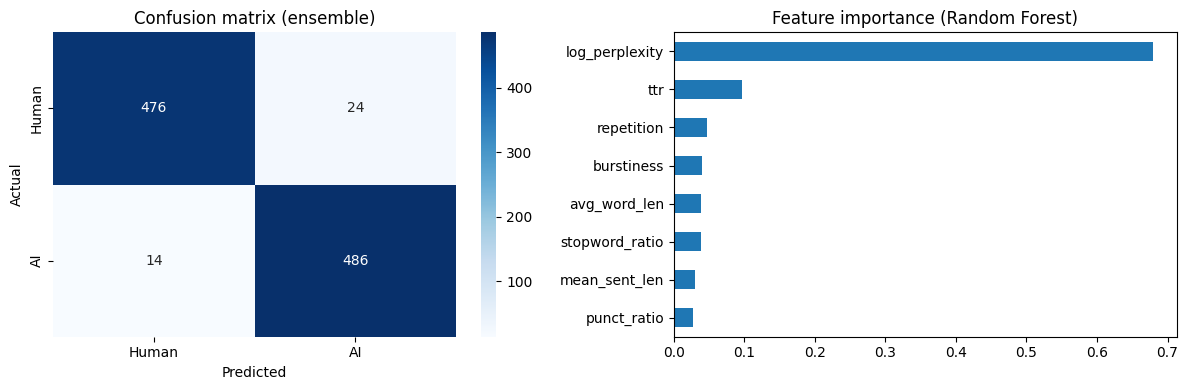

In [8]:
results = {}
for name, m in [("Random Forest", rf), ("SVM", svm), ("Logistic Regression", lr), ("ENSEMBLE", ens)]:
    if name != "ENSEMBLE":
        m.fit(Xtr, y_train)
    results[name] = accuracy_score(y_test, m.predict(Xte))
print(pd.Series(results).round(4).to_string(), "\n")

pred = ens.predict(Xte)
print(classification_report(y_test, pred, target_names=["Human", "AI"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Human", "AI"], yticklabels=["Human", "AI"])
ax[0].set_title("Confusion matrix (ensemble)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
imp.plot.barh(ax=ax[1], title="Feature importance (Random Forest)")
plt.tight_layout(); plt.show()

## 9. Sentence-level analysis and explanation
For each sentence we take it **plus its neighbours** (a 3-sentence window), compute features, and get P(AI). The **reason** is the feature pushing the verdict hardest (Logistic Regression coefficient x standardised value).

In [9]:
lr_exp = ens.named_estimators_["lr"]

def explain(z, p, k=2):
    contrib = lr_exp.coef_[0] * z
    order = np.argsort(-contrib) if p >= 0.5 else np.argsort(contrib)
    out = []
    for j in order[:k]:
        if abs(contrib[j]) < 0.15:
            continue
        out.append(f"{NICE[FEATS[j]]} is {'high' if z[j] > 0 else 'low'}")
    return out

def analyze(text):
    sents = split_sents(text, 1)
    out = []
    for i, s in enumerate(sents):
        ctx = " ".join(sents[max(0, i - 1): i + 2])
        z = scaler.transform(pd.DataFrame([extract(ctx)])[FEATS])[0]
        p = float(ens.predict_proba(pd.DataFrame([z], columns=FEATS))[0, 1])
        out.append({"sentence": s, "p_ai": p, "reasons": explain(z, p)})
    return out

def colour(p):
    g, r = np.array([46, 160, 67]), np.array([218, 54, 61])
    c = (g + (r - g) * p).astype(int)
    return f"rgba({c[0]},{c[1]},{c[2]},0.38)"

def render(text):
    res = analyze(text)
    if not res:
        return "<p>Please paste some text (at least one full sentence).</p>"
    mean_p = float(np.mean([r["p_ai"] for r in res]))
    flagged = sum(r["p_ai"] >= 0.5 for r in res)
    verdict = ("Likely AI-generated" if mean_p >= 0.6 else
               "Likely human-written" if mean_p <= 0.4 else "Mixed / uncertain")
    h = [f"<div style='font-family:sans-serif;color:#111;background:#fff;padding:14px;border-radius:8px'>",
         f"<h3 style='margin:0 0 6px'>{verdict} &mdash; {mean_p*100:.0f}% AI</h3>",
         f"<div style='font-size:13px;margin-bottom:10px'>{flagged} of {len(res)} sentences look AI-like. "
         "Hover over a sentence for details.</div><div style='line-height:2'>"]
    for r in res:
        tip = f"P(AI) = {r['p_ai']*100:.0f}%"
        if r["reasons"]:
            tip += " | " + "; ".join(r["reasons"])
        h.append(f"<span title='{html.escape(tip, quote=True)}' "
                 f"style='background:{colour(r['p_ai'])};padding:2px 3px;border-radius:4px'>"
                 f"{html.escape(r['sentence'])}</span> ")
    h.append("</div><hr><b>Why each sentence was flagged</b><ul style='font-size:13px'>")
    for r in res:
        icon = "🔴" if r["p_ai"] >= 0.6 else "🟢" if r["p_ai"] <= 0.4 else "🟡"
        why = "; ".join(r["reasons"]) or "no strong single signal"
        h.append(f"<li>{icon} <i>{html.escape(r['sentence'][:60])}...</i> "
                 f"<b>{r['p_ai']*100:.0f}% AI</b>: {why}</li>")
    h.append("</ul><div style='font-size:12px'>Legend: "
             "<span style='background:rgba(46,160,67,.38);padding:2px 6px'>human-like</span> "
             "<span style='background:rgba(218,54,61,.38);padding:2px 6px'>AI-like</span></div></div>")
    return "".join(h)

## 10. Live demo: run this cell and open the public link

In [10]:
import gradio as gr

EXAMPLES = [
 ["Artificial intelligence is a transformative technology that has the potential to revolutionize numerous industries. "
  "It offers significant benefits, including increased efficiency, improved decision-making, and enhanced productivity. "
  "However, it is important to consider the ethical implications and ensure responsible development and deployment."],
 ["Honestly I had no idea what I was doing in the lab yesterday. Spilled half the solution, then my partner laughed so hard "
  "he dropped the beaker! Anyway, we redid it and the colour finally changed, which was kind of satisfying."],
]

demo = gr.Interface(
    fn=render,
    inputs=gr.Textbox(lines=10, label="Paste text here (3+ sentences works best)"),
    outputs=gr.HTML(label="DeepTrace result"),
    title="DeepTrace: Sentence-Level AI Text Detection",
    description="Green = human-like, Red = AI-like. Hover on a sentence to see why.",
    examples=EXAMPLES, flagging_mode="never",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e6188427075e90134f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Fairness test on Indian-English writing
Collect 30 to 50 **genuinely human** paragraphs from classmates (or your own old essays) and paste them in the list. Any paragraph flagged as AI is a **false positive**. Report this rate in your project, because most commercial detectors don't.

In [12]:
human_samples = [
    # "Paste a paragraph written by a student here...",
    # "Paste another one...",
]

if human_samples:
    scores = [np.mean([r["p_ai"] for r in analyze(t)]) for t in human_samples]
    fp = np.mean([s >= 0.5 for s in scores])
    print(f"Paragraphs: {len(scores)} | mean P(AI): {np.mean(scores):.2f} | false-positive rate: {fp*100:.1f}%")
    plt.hist(scores, bins=10, range=(0, 1)); plt.xlabel("P(AI)"); plt.title("Human student writing"); plt.show()
else:
    print("Add some human-written paragraphs to human_samples first.")

Add some human-written paragraphs to human_samples first.
